# Datos y targets para deteccion

Convierte las mascaras expertas en targets 2D (una caja por region anatomica en cada corte), construye el indice de cortes positivos sin mezclar pacientes entre splits y define `PengwinDetectionDataset`, el dataset que usan el backbone, la segmentacion y el entrenamiento.

- **Entradas:** `splits/dataset.csv` (`Dataset_splits`), `data_mha/` y el preprocesamiento de `Ventaneo_hu`.
- **Salidas:** `resultados/datos/targets/manifest_cortes_positivos.csv`, `resultados/figuras/targets/targets_bounding_boxes_caso_<id>.png` y `resultados/modelos/batch_fijo.pt` (lo usa Cabeza_grid).

## 1. Configuracion

Rutas relativas a la raiz del repositorio y lectura de los archivos que generan los notebooks anteriores. Las definiciones compartidas se cargan por nombre desde el notebook donde viven (`definiciones_notebooks.cargar_definiciones`), sin ejecutar sus celdas de prueba.

In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import SimpleITK as sitk
import torch

# Raiz del repositorio: funciona si el kernel arranca en notebooks/ o en la raiz.
BASE_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").is_file())
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))  # para importar los modulos de src/

from src.definiciones_notebooks import cargar_definiciones

SPLITS_DIR = BASE_DIR / "splits"
from src.rutas import BATCH_FIJO_PT, FIGURAS_DIR, MANIFEST_CSV
NOTEBOOKS_DIR = BASE_DIR / "notebooks"

def to_repo_relative(path):
    """Guarda rutas portables dentro del repositorio."""
    path = Path(path)
    try:
        return path.relative_to(BASE_DIR).as_posix()
    except ValueError:
        return path.as_posix()


def resolve_repo_path(path):
    """Permite leer rutas relativas o absolutas sin romper compatibilidad."""
    path = Path(path)
    if path.is_absolute():
        return path
    return BASE_DIR / path

# Dataset curado y splits generados por Dataset_splits.ipynb
df = pd.read_csv(SPLITS_DIR / "dataset.csv", dtype={"case_id": str})
split_dataset = df
splits = {name: df[df["split"] == name].sort_values("case_id") for name in ("train", "val", "test")}

cargar_definiciones(NOTEBOOKS_DIR / "Ventaneo_hu.ipynb", {"load_mha", "apply_hu_window", "enhance_bone_contrast"}, destino=globals())

3

## 2. Datos y targets para deteccion

Las mascaras expertas `.mha` se convierten en targets 2D. Los IDs 1-10 representan el sacro, 11-20 el coxal izquierdo y 21-30 el coxal derecho. En cada corte se genera una sola bounding box por region anatomica, uniendo sus fragmentos; las instancias originales se conservan para la etapa posterior de segmentacion.

In [ ]:
from PIL import Image
import matplotlib.patches as patches

CLASS_ID_TO_NAME = {1: "sacro", 2: "coxal_izquierdo", 3: "coxal_derecho"}
TARGET_COLORS = {1: "#D9A62E", 2: "#2B8CBE", 3: "#E34A33"}


def instance_to_semantic(label_slice):
    semantic = np.zeros(label_slice.shape, dtype=np.uint8)
    semantic[(label_slice >= 1) & (label_slice <= 10)] = 1
    semantic[(label_slice >= 11) & (label_slice <= 20)] = 2
    semantic[(label_slice >= 21) & (label_slice <= 30)] = 3
    return semantic


def boxes_from_semantic(semantic_mask, min_pixels=20):
    boxes, labels, areas = [], [], []
    for class_id in CLASS_ID_TO_NAME:
        ys, xs = np.nonzero(semantic_mask == class_id)
        if xs.size < min_pixels:
            continue
        x_min, x_max = int(xs.min()), int(xs.max()) + 1
        y_min, y_max = int(ys.min()), int(ys.max()) + 1
        boxes.append([x_min, y_min, x_max, y_max])
        labels.append(class_id)
        areas.append((x_max - x_min) * (y_max - y_min))
    return (
        np.asarray(boxes, dtype=np.float32).reshape(-1, 4),
        np.asarray(labels, dtype=np.int64),
        np.asarray(areas, dtype=np.float32),
    )


def letterbox_pair(image, label, output_size=256):
    height, width = image.shape
    scale = min(output_size / width, output_size / height)
    new_width = max(1, int(round(width * scale)))
    new_height = max(1, int(round(height * scale)))
    offset_x = (output_size - new_width) // 2
    offset_y = (output_size - new_height) // 2

    image_resized = np.asarray(
        Image.fromarray(image.astype(np.float32), mode="F").resize(
            (new_width, new_height), Image.Resampling.BILINEAR
        ), dtype=np.float32
    )
    label_resized = np.asarray(
        Image.fromarray(label.astype(np.int32), mode="I").resize(
            (new_width, new_height), Image.Resampling.NEAREST
        ), dtype=np.int16
    )

    image_out = np.zeros((output_size, output_size), dtype=np.float32)
    label_out = np.zeros((output_size, output_size), dtype=np.int16)
    image_out[offset_y:offset_y + new_height, offset_x:offset_x + new_width] = image_resized
    label_out[offset_y:offset_y + new_height, offset_x:offset_x + new_width] = label_resized
    return image_out, label_out, {"scale": scale, "offset_x": offset_x, "offset_y": offset_y}


def build_detection_target(label_slice, case_id, slice_index, min_pixels=20):
    semantic = instance_to_semantic(label_slice)
    boxes, labels, areas = boxes_from_semantic(semantic, min_pixels)
    instance_ids = np.unique(label_slice)
    instance_ids = instance_ids[instance_ids != 0].astype(np.int64)
    return {
        "case_id": case_id,
        "slice_index": int(slice_index),
        "boxes": boxes,
        "labels": labels,
        "areas": areas,
        "class_names": [CLASS_ID_TO_NAME[int(label)] for label in labels],
        "semantic_mask": semantic,
        "instance_mask": label_slice.astype(np.int16),
        "instance_ids": instance_ids,
    }

In [ ]:
# Indice de cortes positivos sin mezclar pacientes entre splits
split_by_case = dict(zip(split_dataset["case_id"], split_dataset["split"]))
manifest_rows = []

for _, row in df.iterrows():
    label_volume_case = sitk.GetArrayFromImage(
        sitk.ReadImage(str(resolve_repo_path(row["label_path"])))
    )
    for slice_index, label_slice in enumerate(label_volume_case):
        semantic = instance_to_semantic(label_slice)
        _, labels, _ = boxes_from_semantic(semantic, min_pixels=20)
        if not labels.size:
            continue
        instance_ids = np.unique(label_slice)
        instance_ids = instance_ids[instance_ids != 0]
        manifest_rows.append({
            "split": split_by_case[row["case_id"]],
            "case_id": row["case_id"],
            "slice_index": slice_index,
            "n_regions": len(labels),
            "regions": "|".join(CLASS_ID_TO_NAME[int(value)] for value in labels),
            "n_instances": len(instance_ids),
        })

slice_manifest = pd.DataFrame(manifest_rows)
targets_dir = MANIFEST_CSV.parent         # resultados/datos/targets
targets_dir.mkdir(parents=True, exist_ok=True)
slice_manifest.to_csv(targets_dir / "manifest_cortes_positivos.csv", index=False)

print(slice_manifest.groupby("split").agg(
    casos=("case_id", "nunique"),
    cortes_positivos=("slice_index", "size"),
    promedio_regiones=("n_regions", "mean"),
).round(2))

case_sets = {
    split: set(group["case_id"])
    for split, group in slice_manifest.groupby("split")
}
assert not (case_sets["train"] & case_sets["val"])
assert not (case_sets["train"] & case_sets["test"])
assert not (case_sets["val"] & case_sets["test"])
print("Fuga de pacientes entre splits: 0")

       casos  cortes_positivos  promedio_regiones
split                                            
test      20              4897               2.57
train     75             18072               2.58
val        5              1265               2.55
Fuga de pacientes entre splits: 0


C:\Users\juana\AppData\Local\Temp\ipykernel_25552\2922264119.py:43: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(image.astype(np.float32), mode="F").resize(
C:\Users\juana\AppData\Local\Temp\ipykernel_25552\2922264119.py:48: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(label.astype(np.int32), mode="I").resize(


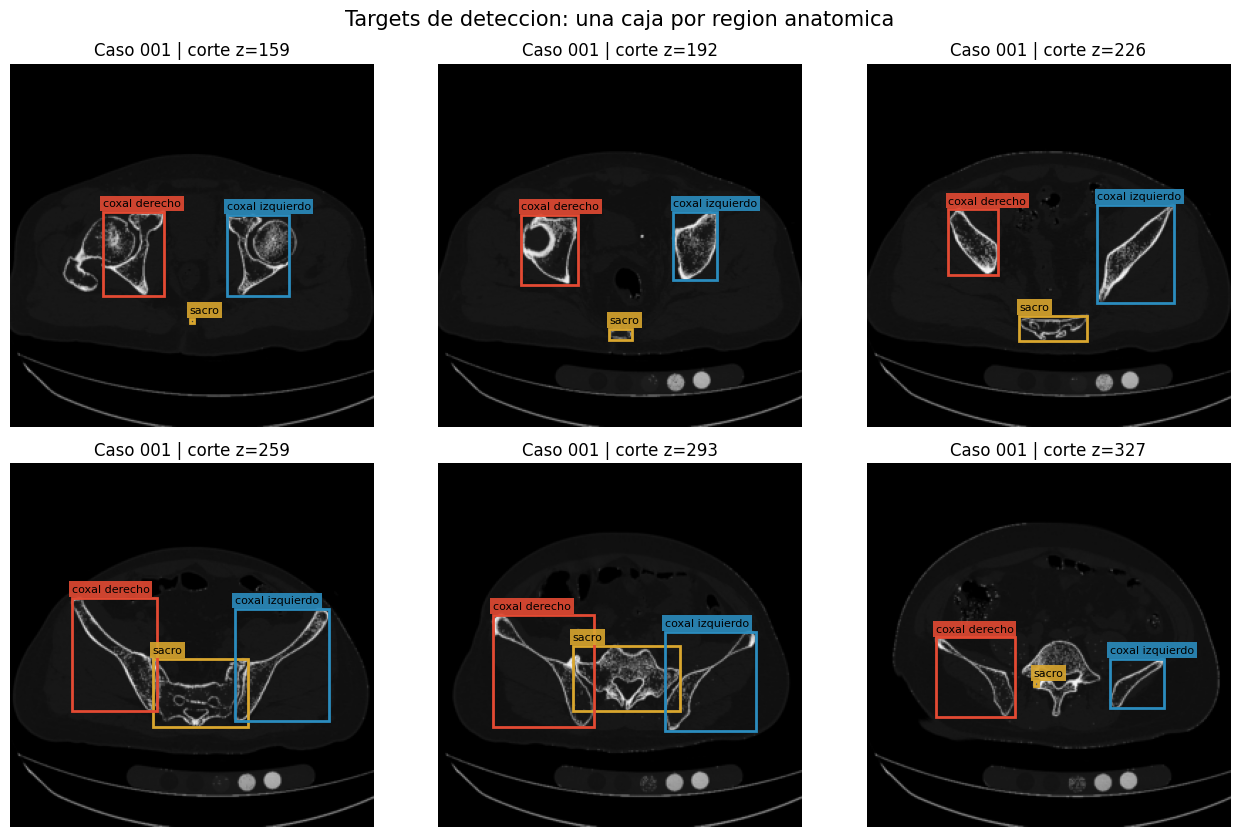

Evidencia guardada en: evidencias/datos_targets/targets_bounding_boxes_caso_001.png


In [ ]:
# Evidencia visual de las cajas generadas
case_id_targets = splits["train"].iloc[0]["case_id"]
case_row = df[df["case_id"] == case_id_targets].iloc[0]
image_targets = sitk.GetArrayFromImage(
    sitk.ReadImage(str(resolve_repo_path(case_row["image_path"])))
).astype(np.float32)
label_targets = sitk.GetArrayFromImage(
    sitk.ReadImage(str(resolve_repo_path(case_row["label_path"])))
).astype(np.int16)

case_manifest = slice_manifest[
    (slice_manifest["case_id"] == case_id_targets) & (slice_manifest["n_regions"] == 3)
]
positions = np.linspace(0, len(case_manifest) - 1, 6).astype(int)
preview_slices = case_manifest.iloc[positions]["slice_index"].astype(int).tolist()

fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
for axis, slice_index in zip(axes.ravel(), preview_slices):
    image = apply_hu_window(image_targets[slice_index])
    image = enhance_bone_contrast(image)
    image, label, transform = letterbox_pair(image, label_targets[slice_index], 256)
    scaled_min_pixels = max(1, int(round(20 * transform["scale"] ** 2)))
    target = build_detection_target(label, case_id_targets, slice_index, scaled_min_pixels)
    axis.imshow(image, cmap="gray", vmin=0, vmax=1)
    for box, class_id in zip(target["boxes"], target["labels"]):
        x_min, y_min, x_max, y_max = box
        color = TARGET_COLORS[int(class_id)]
        axis.add_patch(patches.Rectangle(
            (x_min, y_min), x_max - x_min, y_max - y_min,
            linewidth=2, edgecolor=color, facecolor="none"
        ))
        axis.text(
            x_min, max(8, y_min - 4),
            CLASS_ID_TO_NAME[int(class_id)].replace("_", " "),
            fontsize=8, color="black",
            bbox={"facecolor": color, "alpha": 0.9, "pad": 2, "edgecolor": "none"},
        )
    axis.set_title(f"Caso {case_id_targets} | corte z={slice_index}")
    axis.axis("off")

fig.suptitle("Targets de deteccion: una caja por region anatomica", fontsize=15)
fig.tight_layout()
(FIGURAS_DIR / "targets").mkdir(parents=True, exist_ok=True)
targets_preview_path = FIGURAS_DIR / "targets" / f"targets_bounding_boxes_caso_{case_id_targets}.png"
fig.savefig(targets_preview_path, dpi=180, bbox_inches="tight")
plt.show()
print("Evidencia guardada en:", to_repo_relative(targets_preview_path))

## 3. Dataset para integracion con el modelo

El dataset devuelve la imagen con forma `(canales, 256, 256)` y un diccionario con cajas `xyxy`, clases, areas, mascaras e identificadores. Puede producir NumPy o tensores PyTorch y usa un `collate` para cantidades variables de cajas.

In [ ]:
from matplotlib.pylab import record


class PengwinDetectionDataset:
    def __init__(self, split="train", image_size=256, channels=1, as_torch=False):
        if split not in {"train", "val", "test"}:
            raise ValueError("split debe ser train, val o test")
        if channels not in {1, 3}:
            raise ValueError("channels debe ser 1 o 3")
        self.image_size = image_size
        self.channels = channels
        self.as_torch = as_torch
        self.records = slice_manifest[slice_manifest["split"] == split][
            ["case_id", "slice_index"]
        ].to_dict("records")
        self._cached_case_id = None

    def __len__(self):
        return len(self.records)

    def _load_case(self, case_id):
        if case_id != self._cached_case_id:
            row = df[df["case_id"] == case_id].iloc[0]
            image_itk = sitk.ReadImage(str(resolve_repo_path(row["image_path"])))
            label_itk = sitk.ReadImage(str(resolve_repo_path(row["label_path"])))
            self._image = sitk.GetArrayFromImage(image_itk).astype(np.float32)
            self._label = sitk.GetArrayFromImage(label_itk).astype(np.int16)
            self._spacing = tuple(float(value) for value in image_itk.GetSpacing())
            self._cached_case_id = case_id
        return self._image, self._label, self._spacing

    def __getitem__(self, index):
        record = self.records[index]
        image_volume, label_volume, spacing = self._load_case(record["case_id"])
        image = apply_hu_window(image_volume[record["slice_index"]])
        image = enhance_bone_contrast(image) 
        image, label, transform = letterbox_pair(
            image, label_volume[record["slice_index"]], self.image_size
        )
        min_pixels = max(1, int(round(20 * transform["scale"] ** 2)))
        target = build_detection_target(
            label, record["case_id"], record["slice_index"], min_pixels
        )
        target["spacing_xyz_mm"] = spacing
        target["transform"] = transform
        image = image[None, ...]
        if self.channels == 3:
            image = np.repeat(image, 3, axis=0)
        image = image.astype(np.float32)

        if not self.as_torch:
            return image, target

        import torch
        tensor_target = {
            **target,
            "boxes": torch.from_numpy(target["boxes"]),
            "labels": torch.from_numpy(target["labels"]),
            "areas": torch.from_numpy(target["areas"]),
            "semantic_mask": torch.from_numpy(target["semantic_mask"].astype(np.int64)),
            "instance_mask": torch.from_numpy(target["instance_mask"].astype(np.int64)),
            "image_id": torch.tensor([index], dtype=torch.int64),
        }
        return torch.from_numpy(image), tensor_target


def detection_collate(batch):
    images, targets = zip(*batch)
    return list(images), list(targets)


train_detection_dataset = PengwinDetectionDataset(split="train", as_torch=False)
sample_image, sample_target = train_detection_dataset[0]
print("Cortes positivos de entrenamiento:", len(train_detection_dataset))
print("Forma de imagen:", sample_image.shape)
print("Forma de cajas:", sample_target["boxes"].shape)
print("Clases:", sample_target["class_names"])

Cortes positivos de entrenamiento: 18072
Forma de imagen: (1, 256, 256)
Forma de cajas: (1, 4)
Clases: ['coxal_izquierdo']


C:\Users\juana\AppData\Local\Temp\ipykernel_25552\2922264119.py:43: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(image.astype(np.float32), mode="F").resize(
C:\Users\juana\AppData\Local\Temp\ipykernel_25552\2922264119.py:48: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(label.astype(np.int32), mode="I").resize(


In [ ]:
# Regenerar batch_fijo.pt con el preprocesamiento actualizado (Otsu + CLAHE)
ds_fijo = PengwinDetectionDataset(split="train", as_torch=True)

# Mismos 6 casos "representativos" que ya usabas (o ajusta los indices si quieres otros)
idxs_fijos = np.linspace(0, len(ds_fijo) - 1, 6).astype(int)
muestras_fijas = [ds_fijo[int(i)] for i in idxs_fijos]

batch_fijo = {
    "imgs": torch.stack([s[0] for s in muestras_fijas]),
    "boxes": [s[1]["boxes"] for s in muestras_fijas],
    "labels": [s[1]["labels"] for s in muestras_fijas],
    "case_ids": [s[1]["case_id"] for s in muestras_fijas],
    "slice_index": [s[1]["slice_index"] for s in muestras_fijas],
}

batch_path = BATCH_FIJO_PT
batch_path.parent.mkdir(parents=True, exist_ok=True)
torch.save(batch_fijo, batch_path)
print(f"batch_fijo.pt regenerado en: {to_repo_relative(batch_path)}")
print(f"Imagenes: {batch_fijo['imgs'].shape} | dtype: {batch_fijo['imgs'].dtype}")
print(f"Rango de intensidades: ({batch_fijo['imgs'].min():.3f}, {batch_fijo['imgs'].max():.3f})")

C:\Users\juana\AppData\Local\Temp\ipykernel_25552\2922264119.py:43: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(image.astype(np.float32), mode="F").resize(
C:\Users\juana\AppData\Local\Temp\ipykernel_25552\2922264119.py:48: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(label.astype(np.int32), mode="I").resize(


batch_fijo.pt regenerado en: evidencias/batch_fijo.pt
Imagenes: torch.Size([6, 1, 256, 256]) | dtype: torch.float32
Rango de intensidades: (0.000, 0.998)
